### 環境初始化

##### 掛載Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/vllm-inference-optimization

Mounted at /content/drive
/content/drive/MyDrive/vllm-inference-optimization


##### Git

In [2]:
!git config --global user.name "WalterOuO"
!git config --global user.email "walterlai@gapp.nthu.edu.tw"

In [ ]:
# !git rm -r --cached . # 不要隨便用, 會把過去git紀錄全清空

# 如果要強制修改上一次push的所有file的commit：用--amend，push 尾巴加上 -f
# !git commit --amend -m "Initial Commit"

# 如果上一次push的file只有一個檔案要修改commit:
# !git reset HEAD~1 --soft   # 用 reset 把上一次的紀錄打開: HEAD~1就是上一次, HEAD~2就是上兩次
# !git reset HEAD .      # 把所有檔案先移出暫存區
# !git add .          # 再把上次push的所有檔案加進去
# !git reset somefile     # 唯獨把要修改commit的檔案移出暫存區
# !git commit -m "原本commit" # 把不用改的檔案commit就寫原本commit
# !git add app/.qdrant-initialized # 再把要改的檔案加入暫存區
# !git commit -m "new commit" # 再單獨修改它的新commit
# !git push -u origin main -f # 強制覆蓋線上的錯誤紀錄

In [ ]:
# feat	 新增功能 (Feature)
# fix	  修復 Bug (Bug Fix)
# docs	 僅修改文件 (Documentation)
# style	 不影響程式碼運作的格式調整（如空格、分號、缩排）
# refactor 輸出不變時重構程式碼（既不是新增功能，也不是修補 Bug）
# perf	 效能優化 (Performance)
# test	 增加或修改測試代碼 (Test)
# chore	 建構流程或輔助工具的變動（如 CI/CD、套件版號更新）
# revert	撤銷先前的 commit

In [ ]:
!git add .
!git commit -m "feat: Day 1 model weight quantization exp done"
!git push

[master (root-commit) b74537e] Initial commit.
 24 files changed, 171 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 README.md
 create mode 100644 configs/base_config.yaml
 create mode 100644 configs/day1_awq.yaml
 create mode 100644 configs/day2_kv_fp8.yaml
 create mode 100644 configs/day3_prefix_caching.yaml
 create mode 100644 configs/day4_kv_offloading.yaml
 create mode 100644 configs/day5_speculative.yaml
 create mode 100644 data/prompts/benchmark_prompts.json
 create mode 100644 notebooks/colab_runner.ipynb
 create mode 100644 requirements.txt
 create mode 100644 scripts/run_all.sh
 create mode 100644 src/__init__.py
 create mode 100644 src/experiments/__init__.py
 create mode 100644 src/experiments/base_experiment.py
 create mode 100644 src/experiments/day1_awq_runner.py
 create mode 100644 src/experiments/day2_kv_fp8_runner.py
 create mode 100644 src/experiments/day3_prefix_runner.py
 create mode 100644 src/experiments/day4_offload_runner.py
 create mode 10064

##### 環境檢查

In [3]:
!nvidia-smi

import torch
print(f"CUDA 是否可用: {torch.cuda.is_available()}")
if torch.cuda.is_available():
  print(f"GPU 型號: {torch.cuda.get_device_name(0)}")
  print(f"VRAM 總容量: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

Wed Oct 21 14:22:35 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

##### 安裝依賴套件

In [4]:
!pip install -q -r requirements.txt

print("✅ 所有依賴套件已完成安裝！")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 kB 1.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 326.5/326.5 MB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 526.6/526.6 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 27.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.7/211.7 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 504.7/504.7 kB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.4/45.4 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 31.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.2/366.2 MB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206

##### 執行Baseline實驗

In [5]:
!python src/experiments/day1_awq_runner.py --mode baseline --config configs/day1_awq.yaml

========== 啟動 Day 1 實驗: BASELINE ==========
模型 ID: Qwen/Qwen2.5-3B-Instruct
Prompt 來源: data/prompts/benchmark_prompts.json
config.json: 100% 661/661 [00:00<00:00, 3.35MB/s]
🔍 [動態模型結構解析] 總參數量: 3.40 B (3,396,861,952 params)
🔍 [動態權重計算] 理論模型權重佔用: 6.33 GB
🚀 成功載入 30 個內容獨立的 Prompts (高併發壓測)
(MainProcess pid=5344) INFO 10-21 14:30:15 [api_utils.py:286] non-default args: {'trust_remote_code': True, 'dtype': 'float16', 'gpu_memory_utilization': 0.85, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-3B-Instruct'}
(MainProcess pid=5344) INFO 10-21 14:30:35 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=5344) WARNING 10-21 14:30:35 [model.py:2498] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=5344) INFO 10-21 14:30:35 [model.py:2152] Using max model len 32768
(MainProcess pid=5344) INFO 10-21 14:30:35 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=8192.
model.safetensors.index.json: 100% 35.6k/35.6k [00:00<00:00, 93.0MB/s]
Parse safete

##### 執行優化實驗

In [6]:
!python src/experiments/day1_awq_runner.py --mode awq --config configs/day1_awq.yaml

========== 啟動 Day 1 實驗: AWQ ==========
模型 ID: Qwen/Qwen2.5-3B-Instruct-AWQ
Prompt 來源: data/prompts/benchmark_prompts.json
config.json: 100% 839/839 [00:00<00:00, 4.43MB/s]
🔍 [動態模型結構解析] 總參數量: 3.40 B (3,396,861,952 params)
🔍 [動態權重計算] 理論模型權重佔用: 1.82 GB
🚀 成功載入 30 個內容獨立的 Prompts (高併發壓測)
(MainProcess pid=6810) INFO 10-21 14:34:54 [api_utils.py:286] non-default args: {'trust_remote_code': True, 'dtype': 'float16', 'gpu_memory_utilization': 0.85, 'disable_log_stats': True, 'quantization': 'awq', 'model': 'Qwen/Qwen2.5-3B-Instruct-AWQ'}
(MainProcess pid=6810) INFO 10-21 14:34:56 [model.py:733] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=6810) INFO 10-21 14:34:56 [model.py:2152] Using max model len 32768
(MainProcess pid=6810) INFO 10-21 14:34:58 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=8192.
(MainProcess pid=6810) INFO 10-21 14:35:02 [kernel.py:467] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_a

##### 生成圖表對比

====================== Day 1 實驗對照總結 ======================
    mode                        model  concurrency  model_weight_vram_gb  kv_cache_pool_vram_gb  total_reserved_vram_gb  system_tps
baseline     Qwen/Qwen2.5-3B-Instruct           30                  6.33                   5.73                   12.06      279.65
     awq Qwen/Qwen2.5-3B-Instruct-AWQ           30                  1.82                  10.26                   12.08      330.54


/tmp/ipykernel_497/1789403144.py:60: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_497/1789403144.py:60: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_497/1789403144.py:62: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  plt.savefig(chart_path, dpi=300)
/tmp/ipykernel_497/1789403144.py:62: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.savefig(chart_path, dpi=300)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


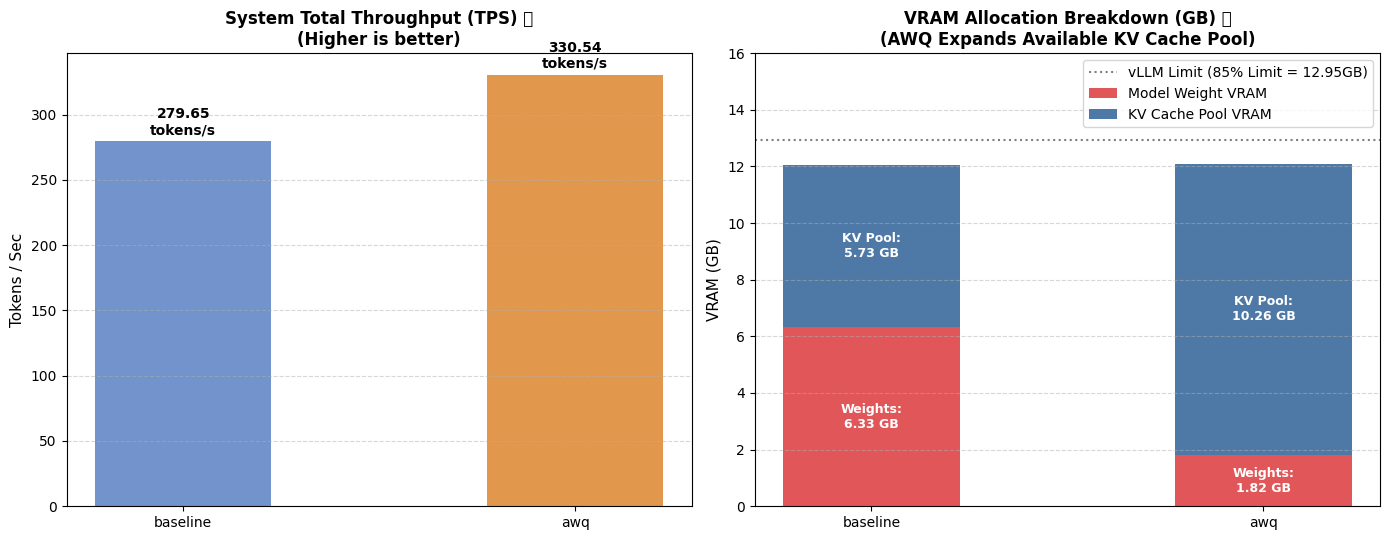


📊 高級視覺化圖表已儲存至: results/charts/day1_awq_comparison.png


In [8]:
# Cell 7: [Report & Visualization] 生成結構化 VRAM 拆解與 TPS 吞吐量對比圖表

import json
import pandas as pd
import matplotlib.pyplot as plt

# 1. 讀取兩組實驗的 JSON 結果
with open("results/raw_logs/day1_baseline.json", "r", encoding="utf-8") as f:
    baseline_res = json.load(f)

with open("results/raw_logs/day1_awq.json", "r", encoding="utf-8") as f:
    awq_res = json.load(f)

df = pd.DataFrame([baseline_res, awq_res])

# 2. 印出文字版摘要對照表 (包含動態拆解指標)
print("====================== Day 1 實驗對照總結 ======================")
summary_cols = ["mode", "model", "concurrency", "model_weight_vram_gb", "kv_cache_pool_vram_gb", "total_reserved_vram_gb", "system_tps"]
print(df[summary_cols].to_string(index=False))

# 3. 繪製對比圖表 (左圖：TPS 吞吐量 / 右圖：VRAM 堆疊結構)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 圖 1: System TPS 對比 (越大越好)
bars = axes[0].bar(df['mode'], df['system_tps'], color=['#7293CB', '#E1974C'], width=0.45)
axes[0].set_title('System Total Throughput (TPS) 🚀\n(Higher is better)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Tokens / Sec', fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height + 3,
                f"{height:.2f}\ntokens/s", ha='center', va='bottom', fontweight='bold')

# 圖 2: VRAM 堆疊結構圖 (顯示模型權重與 KV Cache Pool 的消長)
modes = df['mode']
weight_vram = df['model_weight_vram_gb']
kv_pool_vram = df['kv_cache_pool_vram_gb']

# 繪製堆疊柱狀圖 (Model Weights 在下，KV Cache Pool 在上)
p1 = axes[1].bar(modes, weight_vram, width=0.45, label='Model Weight VRAM', color='#E15759')
p2 = axes[1].bar(modes, kv_pool_vram, width=0.45, bottom=weight_vram, label='KV Cache Pool VRAM', color='#4E79A7')

axes[1].set_title('VRAM Allocation Breakdown (GB) 📊\n(AWQ Expands Available KV Cache Pool)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('VRAM (GB)', fontsize=11)
axes[1].set_ylim(0, 16) # 設定最高為 T4 顯存上限 15-16GB
axes[1].axhline(y=12.95, color='gray', linestyle=':', label='vLLM Limit (85% Limit = 12.95GB)')
axes[1].legend(loc='upper right')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# 在柱狀圖上標註數值
for i in range(len(df)):
    # 標註模型權重 GB
    axes[1].text(i, weight_vram[i]/2, f"Weights:\n{weight_vram[i]} GB",
                 ha='center', va='center', color='white', fontweight='bold', fontsize=9)
    # 標註 KV Cache Pool GB
    axes[1].text(i, weight_vram[i] + kv_pool_vram[i]/2, f"KV Pool:\n{kv_pool_vram[i]} GB",
                 ha='center', va='center', color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
chart_path = "results/charts/day1_awq_comparison.png"
plt.savefig(chart_path, dpi=300)
plt.show()

print(f"\n📊 高級視覺化圖表已儲存至: {chart_path}")